# Adel, 4: sensitivity analysis

**What you will learn:** rank the parameters by their effect on an output, first one at a time, then all together by
random sampling.

**You need:** tutorials 2 and 3. **Run time:** about 30 seconds.

A **sensitivity analysis** answers: *which parameters matter most for this output?* It tells which parameters need an
accurate measurement or calibration, and which can stay at their defaults.

The plant here is a generated plant with the default four numbers (12 leaves, 4 tillers, longest blade 19 cm long and
1.6 cm wide), so that its size parameters can vary. The outputs are read at day 70 (1050 °Cd), when the plant has most
of its leaves.

## 1. One at a time

Each parameter is changed by −10 % and +10 % around its default, the others kept at their defaults. The relative
change of the outputs is recorded. `variants(..., design="one_at_a_time")` (from metafspm) writes these changes
around the plant's own parameters: the reference, then each value of each parameter alone. The counts (`leaf_number`, `tiller_number`) and the switch `tiller_inclination` are
left out, since 10 % of them is not meaningful.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.adel.simulation import parameters, simulate
from openalea.metafspm.scene.scenarios import variants

DAYS = 70
OUTPUTS = ["haun_stage", "green_leaf_area", "height"]
base = {"leaf_number": 12, "tiller_number": 4, "longest_blade_length": 0.19, "longest_blade_width": 0.016}
studied = ["longest_blade_length", "longest_blade_width", "phyllochron", "blade_duration", "sheath_duration",
           "internode_start", "internode_duration", "senescence_start", "senescence_duration"]
defaults = dict(parameters().set_index("name")["value"], **base)


def outputs(scenario):
    return simulate(scenario, days=DAYS).summary.iloc[-1][OUTPUTS]


changes = variants(base, {name: [0.9 * defaults[name], 1.1 * defaults[name]] for name in studied},
                   design="one_at_a_time")
finals = {label: outputs(scenario) for label, scenario in changes.items()}
reference = finals["base"]
effects = {}
for name in studied:
    low, high = (finals[label] for label in changes if label.startswith(f"{name}="))
    effects[name] = (high - low) / reference          # the relative change over the 20 % range
effects = pd.DataFrame(effects).T.astype(float)
effects.round(3)

,haun_stage,green_leaf_area,height
longest_blade_length,0.000,0.200,0.200
longest_blade_width,0.000,0.200,0.000
phyllochron,-0.107,0.129,-1.162
blade_duration,0.000,0.000,0.000
sheath_duration,0.000,0.000,-0.047
internode_start,0.000,0.000,-0.078
internode_duration,0.000,0.000,-0.031
senescence_start,0.000,0.121,0.000
senescence_duration,0.000,0.029,0.000


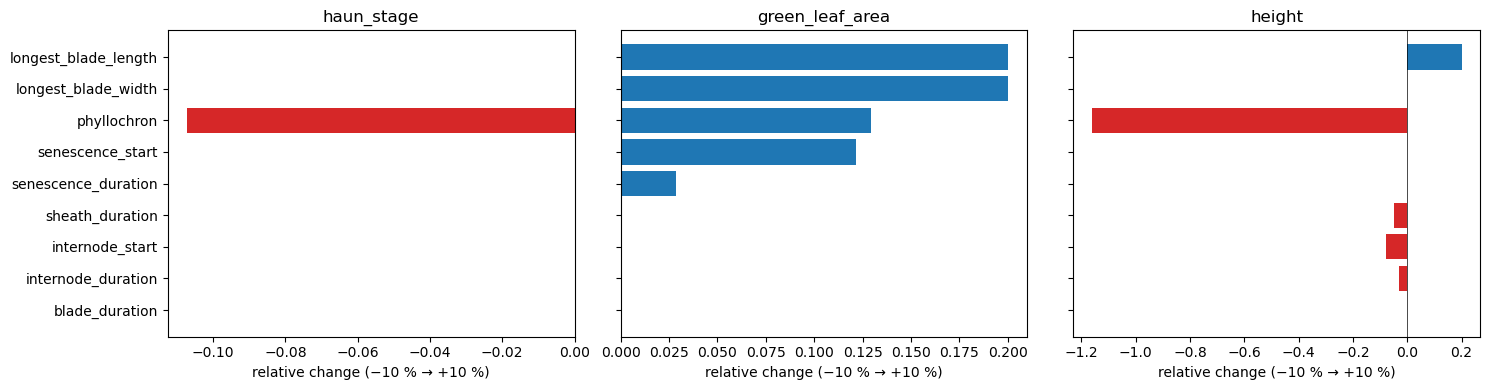

In [2]:
ranked = effects.reindex(effects["green_leaf_area"].abs().sort_values().index)   # one order: by the leaf area's
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, output in zip(axes, OUTPUTS):
    ax.barh(ranked.index, ranked[output], color=np.where(ranked[output] >= 0, "tab:blue", "tab:red"))
    ax.set_title(output); ax.set_xlabel("relative change (−10 % → +10 %)")
    ax.axvline(0, color="k", lw=0.5)
plt.tight_layout()

**Reading the bars** (a "tornado" chart):

- A bar of 0.5 means the output changes by 50 % when the parameter goes from −10 % to +10 %.
- Blue bars increase the output, red ones decrease it.
- The **phyllochron** acts on all three outputs. A longer one makes the leaves appear later, so at a given thermal
  time the Haun stage and the height are lower (red). The green leaf area is higher (blue), because the leaves also
  senesce later (tutorials 2 and 3).
- The **leaf area** also depends on the blades' size: a blade's area is its length times its width, times a shape
  factor. So 10 % more length or width gives about 10 % more area, and the two bars are about 0.2.
- The **height** depends on the internodes' timing (`internode_start`, `internode_duration`) and on the blade length,
  since the internodes are scaled with it.
- A parameter without a bar has no effect on that output at day 70.

This model has no random part, so these effects are exact: there is no noise to compare them with.

## 2. All together: random sampling

Changing one parameter at a time explores only a cross around the defaults: it misses the interactions seen in
tutorial 3. Here four parameters vary together, each between −20 % and +20 % of its default. A **Latin hypercube**
draws 32 combinations that cover each parameter's range evenly (`variants(..., design="sampling")`, from metafspm). For each output, a linear regression on the
standardised parameters gives **standardised regression coefficients** (SRC):

- the SRC of a parameter is the change of the output, in standard deviations, for a change of one standard deviation
  of the parameter;
- when the regression fits well (R² close to 1), the squared SRCs say which share of the output's variance each
  parameter explains.

Dedicated libraries (for example SALib) offer more methods (Morris, Sobol). The principle stays the same: sample the
parameters, run the model, and relate the outputs to the parameters.

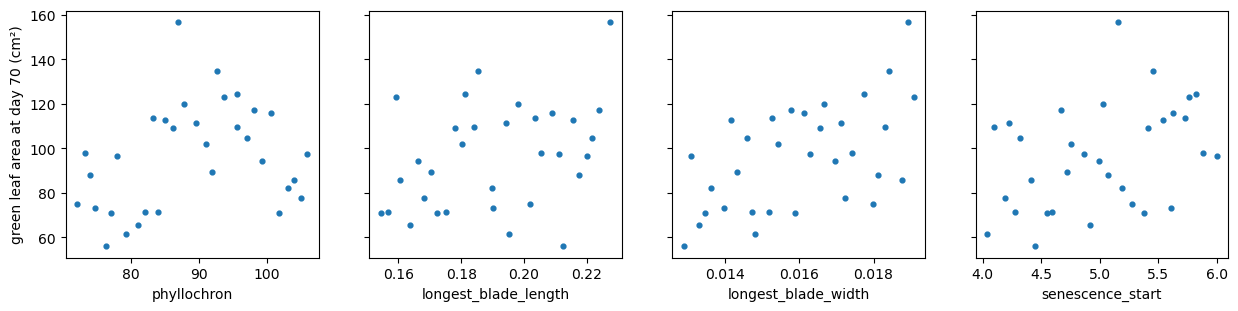

In [3]:
sampled = ["phyllochron", "longest_blade_length", "longest_blade_width", "senescence_start"]
samples = variants(base, {n: (0.8 * defaults[n], 1.2 * defaults[n]) for n in sampled}, design="sampling",
                   samples=32, seed=0)
values = pd.DataFrame(list(samples.values()))[sampled]
results = pd.DataFrame([outputs(scenario) for scenario in samples.values()])

fig, axes = plt.subplots(1, len(sampled), figsize=(15, 3.2), sharey=True)
for ax, name in zip(axes, sampled):
    ax.scatter(values[name], results["green_leaf_area"] * 1e4, s=12)
    ax.set_xlabel(name)
axes[0].set_ylabel("green leaf area at day 70 (cm²)");

In [4]:
standardised = (values - values.mean()) / values.std()
design = np.column_stack([np.ones(len(values)), standardised.values])
rows = {}
for output in OUTPUTS:
    y = (results[output] - results[output].mean()) / results[output].std()
    coefficients, *_ = np.linalg.lstsq(design, y.values, rcond=None)
    fitted = design @ coefficients
    r2 = 1 - np.sum((y.values - fitted) ** 2) / np.sum((y.values - y.values.mean()) ** 2)
    rows[output] = dict(zip(sampled, coefficients[1:]), R2=r2)
pd.DataFrame(rows).T.astype(float).round(2)

,phyllochron,longest_blade_length,longest_blade_width,senescence_start,R2
haun_stage,-0.93,-0.02,0.01,-0.01,0.85
green_leaf_area,0.38,0.40,0.49,0.38,0.66
height,-0.88,0.22,0.00,0.01,0.91


**Reading the table.** Each row is an output, each column a parameter's SRC, and `R2` how well the linear regression
fits. The Haun stage and the height depend mostly on the phyllochron, and the regression fits well. The leaf area
depends on all four, but R² is much lower: a straight line explains only part of it. Its response to the phyllochron
is not linear (it rises, then falls: tutorial 3), and the parameters interact. Methods such as Sobol's quantify such
effects.

## Try it yourself

1. Repeat the one-at-a-time analysis at day 50 (`DAYS = 50`). Does `senescence_start` still matter?
2. Add `internode_start` to the random sample. Which output does it explain?
3. Compute the outputs' range over the random sample (`results.describe()`): how much do 20 % changes of four
   parameters change the leaf area?

**Next:** `05_experimental_data.ipynb`.